# Comparación de modelos de clasificación - Proyecto HTA (SIS)

## KNN, Árbol de Decisión y Regresión Logística

- **Unidad:** un paciente hipertenso (cohorte 2022-2023, sin complicaciones previas y con atenciones en 2024).
- **Objetivo `y`:** ¿tuvo una complicación grave en 2024 (ACV/AIT, infarto, insuficiencia cardíaca, enfermedad renal o fallecimiento)? 1 = Sí, 0 = No.

## 1. Importaciones y Carga de Datos

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_auc_score, roc_curve
)

SEED = 42                     # semilla única para TODO lo aleatorio (split, submuestras, modelos, CV)
np.random.seed(SEED)

# Paleta de colores
color_primary = '#1f77b4'
color_secondary = '#ff7f0e'
color_accent1 = '#2E86AB'
color_accent2 = '#A23B72'

In [2]:
df = pd.read_csv('dataset_consolidado.csv', index_col='paciente')

print(f"Filas y columnas datset: {df.shape}")
df.head()

Filas y columnas datset: (423314, 31)


,edad,masculino,es_lima_frecuente,altitud_msnm,n_atenciones,n_emergencias,n_hospitalizaciones,dias_hosp,n_mediciones_pa,pas_media,...,n_diagnosticos,n_medicamentos,gasto_medicamentos,n_procedimientos,gasto_procedimientos,n_insumos,gasto_insumos,polifarmacia,sin_medicion_pa,y
paciente,,,,,,,,,,,,,,,,,,,,,
000015CA7003D37272A17DE250F6AFE9339F487360EC5001A9B5EBB811E10BFB,75.0,1,0,26.578,19,0,0,0.0,8,108.750000,...,12,8,12.000,36,0.00,1,0.000,1,0,0
000031B49CE1B8437CF896A1D20A1E7A5048DE009526346C0B3840D9E382C493,55.0,0,0,2452.990,37,4,0,0.0,28,135.892850,...,25,24,55.666,46,157.17,13,0.890,1,0,1
0000F157F4A508199E7AB5BC2C578CF314619454313BAA512AB5B2270467C510,63.0,0,1,137.800,51,1,0,0.0,12,123.083336,...,26,27,419.337,88,865.71,55,149.788,1,0,0
0001F8E39760B44806A289A871BFE29613282AC6E89F5E5D6D631745E8455338,63.0,0,0,136.760,40,1,0,0.0,23,128.608690,...,28,11,95.690,91,292.78,14,0.556,1,0,0
0004219B0B4CAB03727B60FFFA9B4F0EAD3271B27BB04B7BD326435BA973BD94,63.0,0,0,43.250,5,2,1,6.0,3,126.666664,...,11,15,64.616,33,517.43,12,23.028,1,0,0


## 2. Exploración rápida
Solo se revisa lo necesario para decidir el preprocesamiento: tamaño, filas repetidas, valores faltantes, tipos de dato y distribución del objetivo.

In [3]:
print(f"Filas (pacientes): {df.shape[0]:,} | Columnas: {df.shape[1]}")

Filas (pacientes): 423,314 | Columnas: 31


In [4]:
df.info()

<class 'pandas.DataFrame'>
Index: 423314 entries, 000015CA7003D37272A17DE250F6AFE9339F487360EC5001A9B5EBB811E10BFB to FDDDE51BE42C8C319E09BDF8C74EF791D8F08CDFC0B8ECBC28AE1749A36B04BD
Data columns (total 31 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   edad                  423311 non-null  float64
 1   masculino             423314 non-null  int64  
 2   es_lima_frecuente     423314 non-null  int64  
 3   altitud_msnm          423314 non-null  float64
 4   n_atenciones          423314 non-null  int64  
 5   n_emergencias         423314 non-null  int64  
 6   n_hospitalizaciones   423314 non-null  int64  
 7   dias_hosp             423314 non-null  float64
 8   n_mediciones_pa       423314 non-null  int64  
 9   pas_media             406863 non-null  float64
 10  pas_max               406863 non-null  float64
 11  pad_media             406863 non-null  float64
 12  pad_max               406863 non-null  float64
 13 

In [5]:
print(f"Pacientes repetidos (índice duplicado): {df.index.duplicated().sum():,}")
print(f"Filas con exactamente las mismas variables (incluida y): {df.duplicated().sum():,}")
print(f"  ...de ellas, con distinto y para las mismas X: "
      f"{df.drop(columns='y').duplicated().sum() - df.duplicated().sum():,}")

Pacientes repetidos (índice duplicado): 0


Filas con exactamente las mismas variables (incluida y): 8


  ...de ellas, con distinto y para las mismas X: 0


In [6]:
# Valores faltantes
faltantes = pd.DataFrame({'Faltantes': df.isnull().sum(),
                          'Porcentaje (%)': (df.isnull().mean() * 100).round(2)})
faltantes[faltantes['Faltantes'] > 0]

,Faltantes,Porcentaje (%)
edad,3,0.00
pas_media,16451,3.89
pas_max,16451,3.89
pad_media,16451,3.89
pad_max,16451,3.89
presion_pulso,16451,3.89
presion_pulso_max,16451,3.89
prop_pa_alta,16451,3.89


In [7]:
# Tipos de datos: ¿hay variables categóricas que codificar?
df.dtypes.value_counts()

int64      18
float64    13
Name: count, dtype: int64

In [8]:
# Distribución del objetivo
pd.DataFrame({'Pacientes': df['y'].value_counts(),
              'Proporción': df['y'].value_counts(normalize=True).round(4)})

,Pacientes,Proporción
y,,
0,400925,0.9471
1,22389,0.0529


In [9]:
# Escalas de las variables
df.drop(columns='y').describe().T[['mean', 'std', 'min', 'max']].round(2)

,mean,std,min,max
edad,65.32,14.26,16.00,110.00
masculino,0.33,0.47,0.00,1.00
es_lima_frecuente,0.28,0.45,0.00,1.00
altitud_msnm,914.92,1227.55,5.18,4705.40
n_atenciones,20.45,18.28,1.00,902.00
n_emergencias,1.05,2.53,0.00,343.00
n_hospitalizaciones,0.17,0.52,0.00,31.00
dias_hosp,1.38,10.71,0.00,991.00
n_mediciones_pa,10.31,9.38,0.00,276.00
pas_media,123.99,16.00,60.00,260.00


| Hallazgo | Consecuencia |
|---|---|
| Hay **valores faltantes** en las variables de presión arterial (pacientes sin ninguna medición) y en algunas edades | KNN y Regresión Logística no aceptan NaN → **imputar** |
| Todas las variables son **numéricas** (binarias 0/1 o continuas) | **No** hace falta Label/One-Hot Encoding |
| Las **escalas son muy distintas** (gasto en miles de soles vs. variables 0/1) | **Estandarizar** para KNN y Regresión Logística (los árboles no lo necesitan) |
| La clase positiva es **≈5%** (desbalance ≈18:1) | El *accuracy* engaña → se usa **ROC-AUC** para elegir hiperparámetros y **`class_weight='balanced'`** |
| `presion_pulso` (media) = `pas_media − pad_media` exactamente, y otras variables muy correlacionadas | Redundancia → se analiza con la **matriz de correlación** (sección 4.2) y se eliminan `dias_hosp` y `pad_media` |

### Modificaciones al dataset 

1. **Imputación por mediana (`SimpleImputer(strategy='median')`)**
   - Se usa la **mediana** y no la media porque presión, edad y gastos tienen colas largas y valores extremos que desplazarían la media.
   - **El imputador solo aprende del train:** `imputer.fit(X_train)` calcula las medianas **únicamente con el conjunto de entrenamiento**. Después, `transform` usa esas medianas para rellenar los vacíos de train **y** de test. El test nunca aporta información (no hay *data leakage*). En los *pipelines* y en la validación cruzada esto ocurre dentro de cada fold.
   - **No se eliminan filas:** los pacientes sin medición de presión tienen **más** complicaciones que el resto. Borrarlos sesgaría la muestra y haría perder un grupo de mayor riesgo.
   - **Se conserva `sin_medicion_pa`**: le indica al modelo que esa presión fue imputada, así que la información de "nunca se midió" no se pierde al imputar.
2. **Estandarización (`StandardScaler`)**, solo para KNN y Regresión Logística, también ajustada **solo con train**. KNN usa distancias y la regresión logística se optimiza por gradiente con regularización: sin escalar, las variables con números grandes (gasto) dominarían. El árbol se entrena **sin escalar**, porque dividen por umbrales y la escala no les afecta.
3. **Desbalance**: `class_weight='balanced'` en el Árbol y la Regresión Logística. Cada paciente con complicación pesa ≈18 veces más en el entrenamiento, así el modelo no puede "ganar" diciendo siempre *sin complicación*. KNN no admite pesos por clase. No se usa **SMOTE** porque crearía pacientes sintéticos con valores intermedios en variables 0/1, y `class_weight` logra el mismo efecto sin inventar datos. **El test nunca se balancea**: debe reflejar la realidad.
4. **Métrica de selección: ROC-AUC.** Con un 5% de positivos, un modelo que siempre dice "0" tiene un 95% de accuracy. El AUC mide cómo el modelo **ordena** a los pacientes por riesgo, sin depender del umbral ni del desbalance.

## 3. Separación de variables y División Entrenamiento-Prueba

In [10]:
y = df['y']
X = df.drop(columns='y')

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,           # 80% entrenamiento, 20% prueba
    random_state=SEED,       # Para resultados replicables
    stratify=y               # Mantiene la proporción de complicaciones en ambos conjuntos
)

pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba'],
    'Muestras': [X_train.shape[0], X_test.shape[0]],
    'Características': [X_train.shape[1], X_test.shape[1]],
    'Complicaciones': [y_train.sum(), y_test.sum()],
    '% Complicaciones': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)]})

,Conjunto,Muestras,Características,Complicaciones,% Complicaciones
0,Entrenamiento,338651,30,17911,5.29
1,Prueba,84663,30,4478,5.29


## 4. Preprocesamiento

### 4.1 Imputación por mediana (fit SOLO con train)

In [11]:
imputer = SimpleImputer(strategy='median')
imputer.fit(X_train)                          # las medianas se calculan SOLO con train

X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X.columns, index=X_train.index)
X_test_imp  = pd.DataFrame(imputer.transform(X_test),  columns=X.columns, index=X_test.index)   # medianas de TRAIN

medianas = pd.Series(imputer.statistics_, index=X.columns)
print("Medianas aprendidas en train (columnas con faltantes):")
print(medianas[X_train.columns[X_train.isnull().any()]].round(2).to_string())
print(f"\nFaltantes después -> train: {X_train_imp.isnull().sum().sum()} | test: {X_test_imp.isnull().sum().sum()}")

Medianas aprendidas en train (columnas con faltantes):


edad                  67.0
pas_media            122.0
pas_max              144.0
pad_media             71.3
pad_max               84.0
presion_pulso         50.0
presion_pulso_max     70.0
prop_pa_alta           0.2



Faltantes después -> train: 0 | test: 0


### 4.2 Matriz de correlación: ¿hay columnas redundantes?
Se calcula **solo con el train** (ya imputado), para que el test no influya en la decisión de eliminar columnas.
- **Pearson** mide la relación lineal.
- **Spearman** mide la relación monótona (por rangos). Es más robusta en variables con muchos ceros y colas largas, como los conteos y gastos.

Dos variables con |r| ≥ 0.9 aportan casi la misma información y una es candidata a eliminarse. Entre 0.7 y 0.9 la redundancia es parcial.

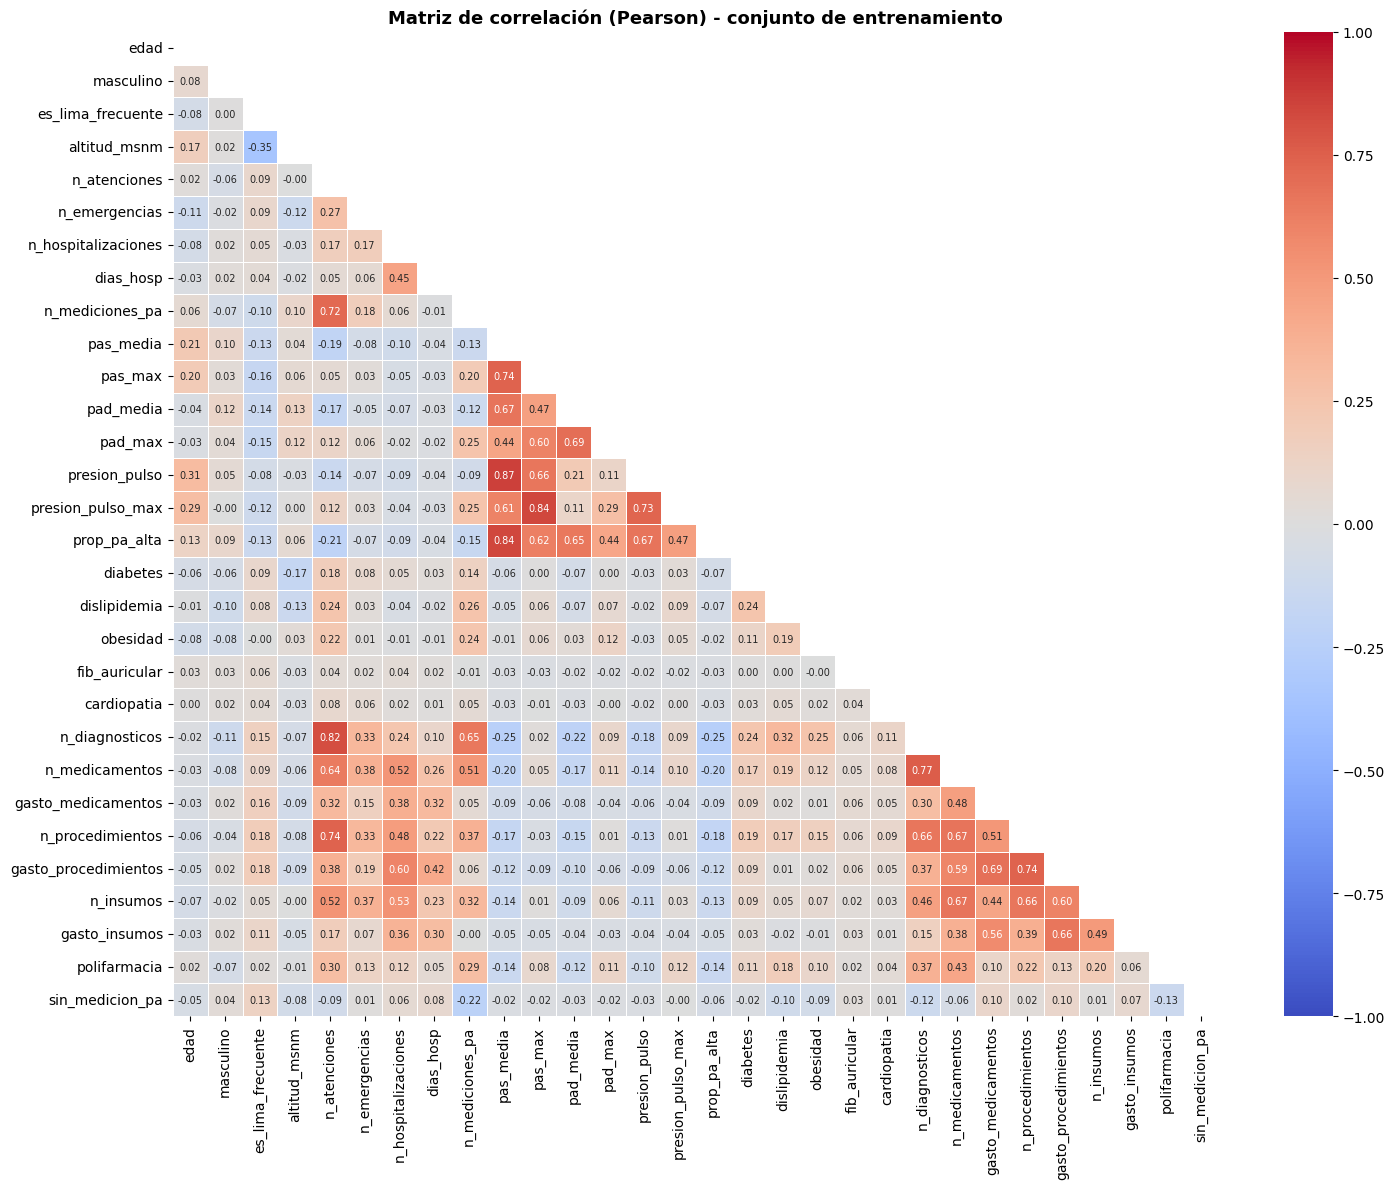

In [12]:
corr = X_train_imp.corr(method='pearson')

mascara = np.triu(np.ones_like(corr, dtype=bool))      # solo el triángulo inferior
fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(corr, mask=mascara, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size': 7}, linewidths=0.5, ax=ax)
ax.set_title('Matriz de correlación (Pearson) - conjunto de entrenamiento', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [13]:
def pares_correlacionados(matriz, umbral):
    # Pares de variables con |correlación| >= umbral, ordenados de mayor a menor
    triangulo = matriz.where(np.triu(np.ones(matriz.shape, dtype=bool), k=1)).stack()
    pares = triangulo[triangulo.abs() >= umbral].sort_values(key=abs, ascending=False)
    return pares.rename('r').round(3).reset_index().rename(columns={'level_0': 'Variable 1', 'level_1': 'Variable 2'})

corr_spearman = X_train_imp.corr(method='spearman')
print("Pares con |r| >= 0.7 (Pearson):")
display(pares_correlacionados(corr, 0.7))
print("Pares con |r| >= 0.7 (Spearman):")
display(pares_correlacionados(corr_spearman, 0.7))

Pares con |r| >= 0.7 (Pearson):


,Variable 1,Variable 2,r
0,pas_media,presion_pulso,0.866
1,pas_max,presion_pulso_max,0.841
2,pas_media,prop_pa_alta,0.839
3,n_atenciones,n_diagnosticos,0.818
4,n_diagnosticos,n_medicamentos,0.765
5,n_atenciones,n_procedimientos,0.742
6,pas_media,pas_max,0.740
7,n_procedimientos,gasto_procedimientos,0.740
8,presion_pulso,presion_pulso_max,0.728
9,n_atenciones,n_mediciones_pa,0.718


Pares con |r| >= 0.7 (Spearman):


,Variable 1,Variable 2,r
0,n_hospitalizaciones,dias_hosp,0.997
1,n_atenciones,n_diagnosticos,0.857
2,pas_media,presion_pulso,0.848
3,pas_media,prop_pa_alta,0.830
4,pas_max,presion_pulso_max,0.824
5,n_diagnosticos,n_medicamentos,0.801
6,n_atenciones,n_mediciones_pa,0.774
7,gasto_procedimientos,gasto_insumos,0.761
8,gasto_medicamentos,gasto_procedimientos,0.757
9,pas_max,prop_pa_alta,0.755


In [14]:
# Relación de cada variable con el objetivo: ante dos variables redundantes, conviene quedarse con la más relacionada con y
X_train_imp.corrwith(y_train).sort_values(key=abs, ascending=False).round(3).to_frame('Correlación con y')

,Correlación con y
n_procedimientos,0.078
gasto_procedimientos,0.075
edad,0.074
n_medicamentos,0.070
gasto_medicamentos,0.068
diabetes,0.065
n_hospitalizaciones,0.059
fib_auricular,0.051
n_diagnosticos,0.050
n_insumos,0.045


#### Interpretación: ¿qué columnas eliminar?

| Par | Correlación | Diagnóstico | Recomendación |
|---|---|---|---|
| `n_hospitalizaciones` – `dias_hosp` | Spearman ≈ **0.997** | Casi idénticas: la mayoría de pacientes tiene 0 en ambas. Pearson es menor solo por algunos días extremos | **Eliminar `dias_hosp`**: se queda `n_hospitalizaciones`, que tiene mayor correlación con `y` |
| `presion_pulso` = `pas_media` − `pad_media` | Dependencia lineal **exacta** (no se ve en un solo par) | Una de las tres es redundante. Para la Regresión Logística es colinealidad perfecta | **Eliminar `pad_media`**: es la de menor relación con `y` (≈0.00), y su información queda en `pas_media` y `presion_pulso` |
| `pas_media` – `presion_pulso` / `prop_pa_alta`; `pas_max` – `presion_pulso_max` | 0.84 – 0.87 | Alta, pero < 0.9: miden aspectos distintos (nivel, rigidez arterial, frecuencia de PA elevada) | Mantener |
| `n_atenciones` – `n_diagnosticos` – `n_medicamentos` – `n_procedimientos` | 0.75 – 0.86 | Todas reflejan la intensidad de uso del sistema de salud | Mantener (redundancia parcial) |

**Impacto esperado:** bajo.
- Los árboles eligen una sola variable por división, así que la redundancia no les afecta.
- En la Regresión Logística, la regularización L2 ya amortigua la colinealidad (todas las combinaciones de C dieron el mismo AUC).
- Eliminar `dias_hosp` y `pad_media` sobre todo **simplifica** el modelo y hace **interpretables** los coeficientes de presión, sin pérdida esperada de AUC.
- **Decisión del equipo: se eliminan `dias_hosp` y `pad_media`** (celda siguiente).

In [15]:
# Eliminar columnas redundantes según la matriz de correlación (calculada solo con train)
COLS_ELIMINAR = ['dias_hosp', 'pad_media']

X           = X.drop(columns=COLS_ELIMINAR)
X_train     = X_train.drop(columns=COLS_ELIMINAR)
X_test      = X_test.drop(columns=COLS_ELIMINAR)
X_train_imp = X_train_imp.drop(columns=COLS_ELIMINAR)
X_test_imp  = X_test_imp.drop(columns=COLS_ELIMINAR)

print(f"Variables restantes: {X_train.shape[1]}")

Variables restantes: 28


### 4.3 Estandarización (fit SOLO con train)
$x_{std} = \frac{x - \mu_{train}}{\sigma_{train}}$

In [16]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_imp), columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test_imp),      columns=X.columns, index=X_test.index)

cols_ej = ['edad', 'pas_media', 'altitud_msnm', 'gasto_procedimientos']
pd.DataFrame({
    'Antes (media)':   X_train_imp[cols_ej].mean(),
    'Antes (std)':     X_train_imp[cols_ej].std(),
    'Después (media)': X_train_scaled[cols_ej].mean(),
    'Después (std)':   X_train_scaled[cols_ej].std()
}).round(3)

,Antes (media),Antes (std),Después (media),Después (std)
edad,65.336,14.254,0.0,1.0
pas_media,123.919,15.712,0.0,1.0
altitud_msnm,914.411,1226.925,0.0,1.0
gasto_procedimientos,307.828,849.430,0.0,1.0


### 4.4 Conjunto de validación
Para elegir hiperparámetros, el entrenamiento se divide de nuevo en *training* (80%) y *validación* (20%). **El test no se toca hasta el final.**

In [17]:
idx_tr, idx_val = train_test_split(X_train.index, test_size=0.2, random_state=SEED, stratify=y_train)
y_tr, y_val = y_train.loc[idx_tr], y_train.loc[idx_val]

def auc_tr_val(modelo, X_tr_, X_val_):
    # Entrena con training y devuelve (AUC train, AUC validación)
    modelo.fit(X_tr_, y_tr)
    return (roc_auc_score(y_tr, modelo.predict_proba(X_tr_)[:, 1]),
            roc_auc_score(y_val, modelo.predict_proba(X_val_)[:, 1]))

print(f"Training: {len(idx_tr):,} | Validación: {len(idx_val):,}")

Training: 270,920 | Validación: 67,731


---

## 5. K-Nearest Neighbors (KNN)

KNN clasifica a un paciente según la mayoría de votos de sus $k$ vecinos más cercanos (distancia euclidiana). Necesita datos **estandarizados**.

### 5.1 Efecto del Hiperparámetro k
KNN es lento para predecir (calcula la distancia a todos los pacientes del train). Por eso el ajuste de $k$ se hace con una **submuestra estratificada de 50,000 pacientes** del training, más el conjunto de validación completo. El modelo final se entrena con **todo** el train.

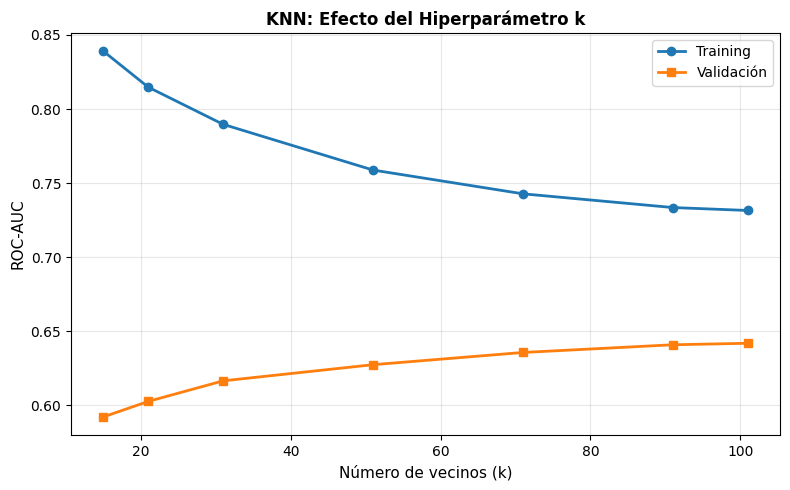

ROC-AUC por k:
  k=15: Train=0.8391, Val=0.5922, Brecha=0.2469
  k=21: Train=0.8148, Val=0.6026, Brecha=0.2121
  k=31: Train=0.7896, Val=0.6165, Brecha=0.1731
  k=51: Train=0.7588, Val=0.6274, Brecha=0.1314
  k=71: Train=0.7428, Val=0.6357, Brecha=0.1071
  k=91: Train=0.7335, Val=0.6409, Brecha=0.0926
  k=101: Train=0.7315, Val=0.6419, Brecha=0.0896


In [18]:
# Submuestra estratificada de training para el ajuste de k
idx_tr_knn, _ = train_test_split(idx_tr, train_size=50_000, random_state=SEED, stratify=y_tr)
y_tr_knn = y_tr.loc[idx_tr_knn]

k_values = [15, 21, 31, 51, 71, 91, 101]
train_scores_knn, val_scores_knn = [], []

for k in k_values:
    knn_temp = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    knn_temp.fit(X_train_scaled.loc[idx_tr_knn], y_tr_knn)
    train_scores_knn.append(roc_auc_score(y_tr_knn, knn_temp.predict_proba(X_train_scaled.loc[idx_tr_knn])[:, 1]))
    val_scores_knn.append(roc_auc_score(y_val, knn_temp.predict_proba(X_train_scaled.loc[idx_val])[:, 1]))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(k_values, train_scores_knn, marker='o', label='Training', color=color_primary, linewidth=2)
ax.plot(k_values, val_scores_knn, marker='s', label='Validación', color=color_secondary, linewidth=2)
ax.set_xlabel('Número de vecinos (k)', fontsize=11)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('KNN: Efecto del Hiperparámetro k', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC por k:")
for k, tr, val in zip(k_values, train_scores_knn, val_scores_knn):
    print(f"  k={k:2d}: Train={tr:.4f}, Val={val:.4f}, Brecha={tr - val:.4f}")

In [19]:
best_k = k_values[int(np.argmax(val_scores_knn))]
print(f"Mejor k: {best_k}")

# Modelo final con ese k en TODO el entrenamiento; se evalúa UNA vez en test
knn_final = KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1)
knn_final.fit(X_train_scaled, y_train)
y_proba_knn = knn_final.predict_proba(X_test_scaled)[:, 1]
y_pred_knn = (y_proba_knn >= 0.5).astype(int)
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_knn):.4f}")

Mejor k: 101


ROC-AUC en TEST: 0.6687


#### Justificación del hiperparámetro elegido (KNN)
- **k elegido: 101** (AUC en validación = 0.6419), el más alto de la grilla `[15, 21, 31, 51, 71, 91, 101]`.
- Con k pequeño, KNN **memoriza** el entrenamiento: con k=15 el AUC en train es 0.84 y en validación 0.59, una brecha de 0.25 (sobreajuste). Al aumentar k, la brecha baja de forma constante (0.090 con k=101) y la validación sube.
- La mejora se va **aplanando**: de 91 a 101 vecinos, el AUC de validación sube solo 0.001. Seguir aumentando k daría ganancias marginales, a cambio de predicciones más lentas.
- Con el modelo final (k=101, todo el train), el AUC en test es **0.669**.

#### ¿Por qué el mejor k siempre es el más alto de la grilla?
En todas las grillas probadas, el mejor $k$ resultó ser **el mayor valor disponible**. Esto no es casualidad: refleja que **KNN suele ser el modelo más débil para datos tabulares administrativos y médicos** como estos, por tres motivos:

1. **Alta dimensionalidad (maldición de la dimensionalidad).** Con ~28 variables heterogéneas (conteos, gastos, indicadores 0/1, presión), las distancias euclidianas entre pacientes se vuelven parecidas: el vecino "más cercano" no es mucho más cercano que uno lejano. Además, KNN da el **mismo peso a todas las variables**, incluidas las que aportan poco (p. ej. `dislipidemia`, `pad_max`), y estas meten ruido en la distancia. Con pocos vecinos el voto es casi aleatorio; solo al promediar muchos (k grande) el ruido se cancela. Por eso el AUC sube con k.
2. **Desbalance de clases (5% de positivos).** Entre los k vecinos de cualquier paciente hay, en promedio, solo un 5% con complicación. Con el umbral de 0.5 casi nunca se alcanza la mayoría, así que KNN **no predice ninguna complicación** (recall = 0). Además, KNN no admite `class_weight`. Un k grande solo mejora el **orden** de las probabilidades (AUC), no la detección.
3. **Costo de cómputo en la inferencia.** KNN no "aprende" un modelo: para predecir a cada paciente calcula la distancia a los **~340,000 pacientes del train**. Es el modelo más lento de predecir, y el costo crece con el tamaño de los datos. Por eso su ajuste se hizo sobre una submuestra, mientras que el árbol y la regresión logística, una vez entrenados, predicen casi al instante.

En cambio, los **árboles** eligen solo las variables útiles en cada división y la **regresión logística** aprende un peso por variable. Ambos manejan mejor las variables irrelevantes y el desbalance (`class_weight='balanced'`). Esto coincide con lo reportado para datos tabulares, donde los modelos basados en árboles y los lineales suelen superar a los basados en distancias.

---

## 6. Árboles de Decisión

Particionan el espacio con preguntas sobre las variables ("¿edad > 70?"). No necesitan estandarización: se entrenan con `X_train_imp`. Se usa `class_weight='balanced'`.

### 6.1 Efecto de la Profundidad

Mejor profundidad: 7


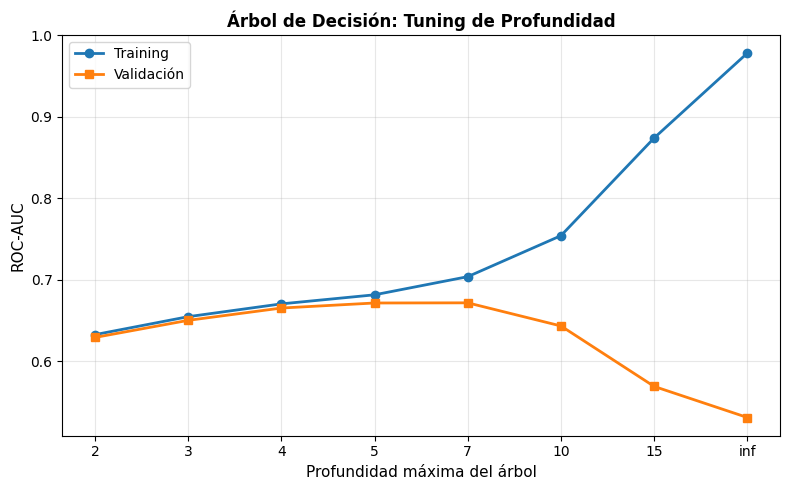

ROC-AUC por profundidad:
  depth=2  : Train=0.6329, Val=0.6294, Brecha=0.0034
  depth=3  : Train=0.6549, Val=0.6504, Brecha=0.0045
  depth=4  : Train=0.6706, Val=0.6655, Brecha=0.0051
  depth=5  : Train=0.6817, Val=0.6717, Brecha=0.0100
  depth=7  : Train=0.7039, Val=0.6719, Brecha=0.0321
  depth=10 : Train=0.7542, Val=0.6435, Brecha=0.1107
  depth=15 : Train=0.8739, Val=0.5694, Brecha=0.3045
  depth=inf: Train=0.9779, Val=0.5314, Brecha=0.4466


In [20]:
depths = [2, 3, 4, 5, 7, 10, 15, None]
train_scores_dt, val_scores_dt = [], []

for depth in depths:
    dt_temp = DecisionTreeClassifier(max_depth=depth, min_samples_split=20,
                                     class_weight='balanced', random_state=SEED)
    tr, val = auc_tr_val(dt_temp, X_train_imp.loc[idx_tr], X_train_imp.loc[idx_val])
    train_scores_dt.append(tr)
    val_scores_dt.append(val)

best_depth = depths[int(np.argmax(val_scores_dt))]
print(f"Mejor profundidad: {best_depth}")

fig, ax = plt.subplots(figsize=(8, 5))
depths_plot = [str(d) if d else 'inf' for d in depths]
x_pos = np.arange(len(depths_plot))
ax.plot(x_pos, train_scores_dt, marker='o', label='Training', color=color_primary, linewidth=2)
ax.plot(x_pos, val_scores_dt, marker='s', label='Validación', color=color_secondary, linewidth=2)
ax.set_xlabel('Profundidad máxima del árbol', fontsize=11)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('Árbol de Decisión: Tuning de Profundidad', fontsize=12, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(depths_plot)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC por profundidad:")
for depth, tr, val in zip(depths_plot, train_scores_dt, val_scores_dt):
    print(f"  depth={depth:3s}: Train={tr:.4f}, Val={val:.4f}, Brecha={tr - val:.4f}")

In [21]:
# Árbol final con la mejor profundidad, entrenado con TODO el train
dt_final = DecisionTreeClassifier(max_depth=best_depth, min_samples_split=20,
                                  class_weight='balanced', random_state=SEED)
dt_final.fit(X_train_imp, y_train)
y_pred_dt = dt_final.predict(X_test_imp)
y_proba_dt = dt_final.predict_proba(X_test_imp)[:, 1]
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_dt):.4f}")

ROC-AUC en TEST: 0.6827


#### Justificación del hiperparámetro elegido (Árbol)
- **Profundidad elegida: 7** (AUC en validación = 0.6719).
- Hasta la profundidad 5, el AUC de validación sube y la brecha train–validación es mínima (≤ 0.01). La profundidad 7 supera a la 5 solo por **0.0002**, con una brecha de 0.032, todavía baja. Se elige 7 porque es la mejor en validación, pero **5 es una alternativa equivalente y más simple** (más fácil de interpretar).
- A partir de la profundidad 10 hay **sobreajuste** claro: el AUC de train sube (0.75 → 0.98) mientras el de validación cae (0.64 → 0.53).
- Con el árbol final, el AUC en test es **0.683**.

### 6.2 Importancia de Características

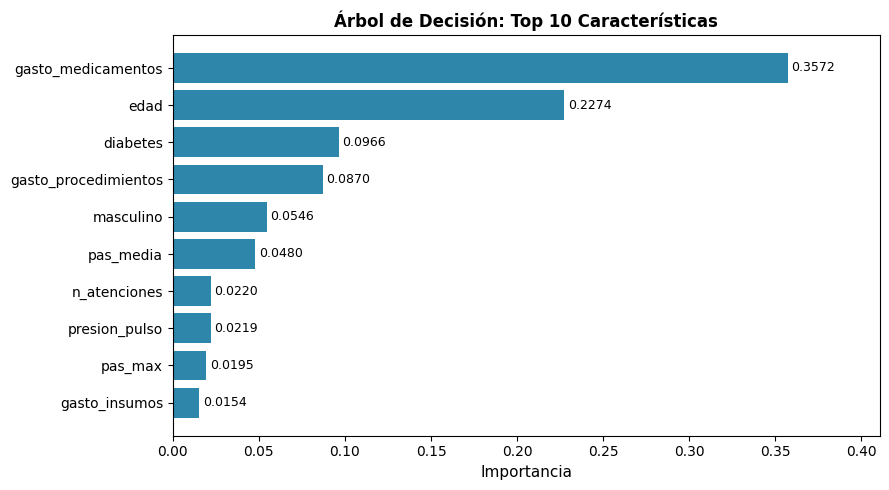

In [22]:
def plot_importancia(modelo, titulo, color):
    imp = pd.DataFrame({'feature': X.columns, 'importance': modelo.feature_importances_}) \
            .sort_values('importance', ascending=False).head(10)
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.barh(imp['feature'], imp['importance'], color=color)
    for i, (_, row) in enumerate(imp.iterrows()):
        ax.text(row['importance'] + 0.002, i, f"{row['importance']:.4f}", va='center', fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel('Importancia', fontsize=11)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlim([0, imp['importance'].max() * 1.15])
    plt.tight_layout()
    plt.show()

plot_importancia(dt_final, 'Árbol de Decisión: Top 10 Características', color_accent1)

---

## 7. Regresión Logística

Modelo lineal que estima $P(y=1|x) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 x_1 + ... + \beta_n x_n)}}$. Necesita datos **estandarizados**. Se usa `class_weight='balanced'` y regularización L2.

### 7.1 Tuning de Hiperparámetros (ejercicio del tutorial)
Se prueban los solvers `lbfgs`, `saga` y `liblinear` con `C ∈ {0.01, 0.1, 1, 10}` ($C$ bajo = regularización fuerte).

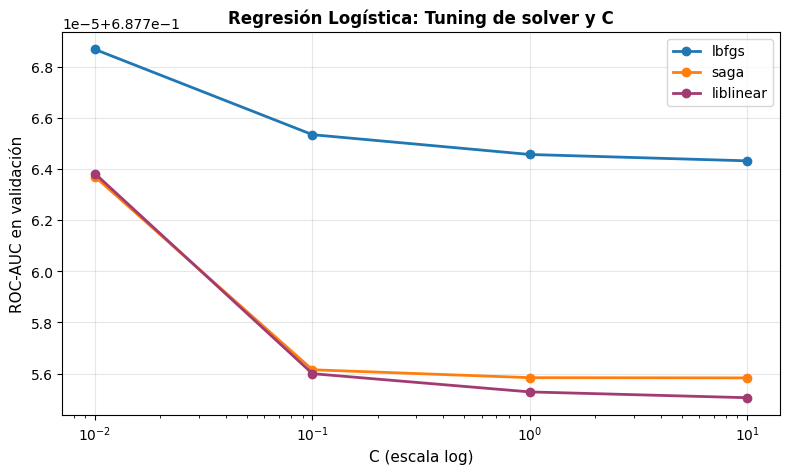

solver,lbfgs,liblinear,saga
C,,,
0.01,0.6878,0.6878,0.6878
0.10,0.6878,0.6878,0.6878
1.00,0.6878,0.6878,0.6878
10.00,0.6878,0.6878,0.6878


In [23]:
solvers = ['lbfgs', 'saga', 'liblinear']
C_values = [0.01, 0.1, 1.0, 10]
resultados_lr = []

with warnings.catch_warnings():
    warnings.simplefilter('ignore', ConvergenceWarning)
    for solver in solvers:
        for C in C_values:
            lr_temp = LogisticRegression(C=C, solver=solver, l1_ratio=0, class_weight='balanced',
                                         max_iter=1000, random_state=SEED)
            tr, val = auc_tr_val(lr_temp, X_train_scaled.loc[idx_tr], X_train_scaled.loc[idx_val])
            resultados_lr.append({'solver': solver, 'C': C, 'AUC train': tr, 'AUC val': val})

resultados_lr = pd.DataFrame(resultados_lr)

fig, ax = plt.subplots(figsize=(8, 5))
for solver, color in zip(solvers, [color_primary, color_secondary, color_accent2]):
    r = resultados_lr[resultados_lr['solver'] == solver]
    ax.plot(r['C'], r['AUC val'], marker='o', label=solver, color=color, linewidth=2)
ax.set_xscale('log')
ax.set_xlabel('C (escala log)', fontsize=11)
ax.set_ylabel('ROC-AUC en validación', fontsize=11)
ax.set_title('Regresión Logística: Tuning de solver y C', fontsize=12, fontweight='bold')
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

resultados_lr.pivot(index='C', columns='solver', values='AUC val').round(4)

In [24]:
mejor_lr = resultados_lr.loc[resultados_lr['AUC val'].idxmax()]
best_solver, best_C = mejor_lr['solver'], mejor_lr['C']
print(f"Mejor combinación: solver={best_solver}, C={best_C} (AUC val={mejor_lr['AUC val']:.4f})")

lr_final = LogisticRegression(C=best_C, solver=best_solver, l1_ratio=0, class_weight='balanced',
                              max_iter=1000, random_state=SEED)
lr_final.fit(X_train_scaled, y_train)
y_pred_lr = lr_final.predict(X_test_scaled)
y_proba_lr = lr_final.predict_proba(X_test_scaled)[:, 1]
print(f"ROC-AUC en TEST: {roc_auc_score(y_test, y_proba_lr):.4f}")

Mejor combinación: solver=lbfgs, C=0.01 (AUC val=0.6878)


ROC-AUC en TEST: 0.6947


#### Justificación del hiperparámetro elegido (Regresión Logística)
- **Combinación elegida: `lbfgs`, C = 0.01** (AUC en validación = 0.6878).
- **Las 12 combinaciones dan el mismo AUC (0.6878).** Con ≈270,000 pacientes y solo 30 variables, hay muchos más datos que parámetros, así que la regularización casi no cambia los coeficientes. Los tres solvers resuelven el mismo problema convexo y llegan a la misma solución.
- Como el resultado empata, se eligió la primera combinación: `lbfgs` (el solver por defecto de sklearn, rápido y estable para L2) y el C más bajo (la regularización más fuerte). Ante un empate, conviene el modelo más regularizado: protege frente a la colinealidad de las variables de presión.
- La brecha train–validación es prácticamente nula: la regresión logística **no sobreajusta**.
- Con el modelo final, el AUC en test es **0.695**.

### 7.2 Coeficientes
Como las variables están estandarizadas, los coeficientes son comparables entre sí: un valor positivo **aumenta** la probabilidad de complicación y uno negativo la **reduce**. Al eliminar `pad_media` desaparece la dependencia exacta con `presion_pulso`. Aun así, `pas_media`, `pas_max`, `presion_pulso` y `prop_pa_alta` siguen correlacionadas (0.74–0.87), así que sus coeficientes deben interpretarse en conjunto.

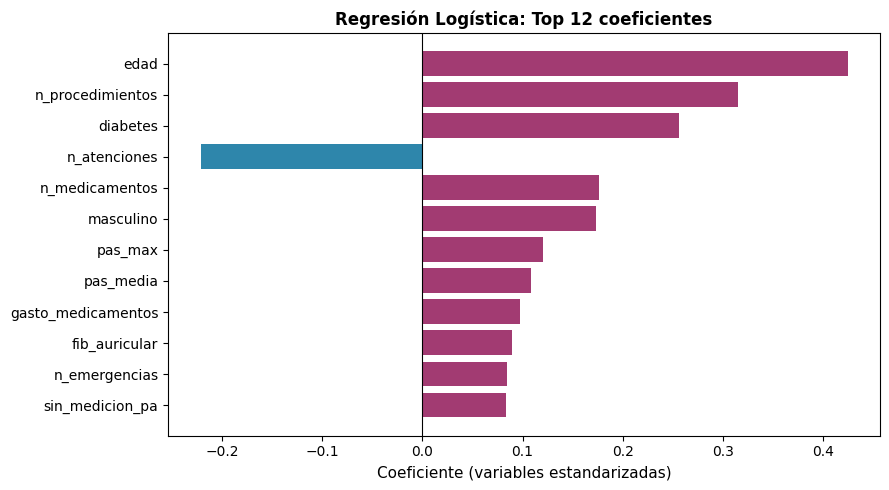

In [25]:
coefs = pd.Series(lr_final.coef_[0], index=X.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(12)

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index, top.values, color=[color_accent2 if v > 0 else color_accent1 for v in top.values])
ax.invert_yaxis()
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Coeficiente (variables estandarizadas)', fontsize=11)
ax.set_title('Regresión Logística: Top 12 coeficientes', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---

## 8. Comparación de Modelos

### 8.1 Métricas de Clasificación (conjunto de prueba)
**Accuracy** engaña con desbalance (decir siempre "sin complicación" da ≈95%). Las métricas relevantes son:
- **Recall**: de los pacientes que sí tuvieron complicación, ¿cuántos detectó el modelo? (un falso negativo es un paciente en riesgo no detectado).
- **Precision**: de los que el modelo marcó como riesgo, ¿cuántos realmente la tuvieron?
- **F1**: equilibrio entre precision y recall.
- **ROC-AUC**: capacidad de **ordenar** a los pacientes por riesgo, independiente del umbral. Es la métrica principal de comparación.

In [26]:
models = {
    'KNN': (y_pred_knn, y_proba_knn),
    'Árbol': (y_pred_dt, y_proba_dt),
    'Reg. Logística': (y_pred_lr, y_proba_lr),
}

metrics_df = pd.DataFrame([{
    'Modelo': name,
    'Accuracy': accuracy_score(y_test, y_pred),
    'Precision': precision_score(y_test, y_pred, zero_division=0),
    'Recall': recall_score(y_test, y_pred),
    'F1-Score': f1_score(y_test, y_pred),
    'ROC-AUC': roc_auc_score(y_test, y_proba)
} for name, (y_pred, y_proba) in models.items()])
metrics_df.round(4)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,KNN,0.9471,0.0000,0.0000,0.0000,0.6687
1,Árbol,0.6297,0.0872,0.6335,0.1532,0.6827
2,Reg. Logística,0.6535,0.0922,0.6275,0.1608,0.6947


> **Nota sobre KNN:** KNN no admite `class_weight`. Con el umbral de 0.5, un paciente solo se marca como riesgo si la mayoría de sus vecinos tuvo complicación, algo raro cuando solo el 5% la tiene. Por eso su *recall* sale muy bajo aunque su AUC no sea malo. Para compararlo de forma justa se usa el AUC, que no depende del umbral.

### 8.2 Curvas ROC

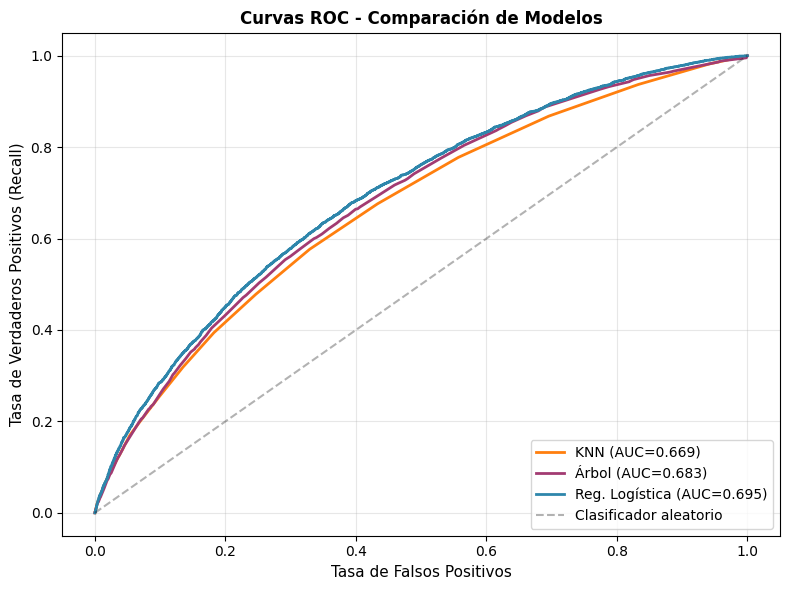

In [27]:
fig, ax = plt.subplots(figsize=(8, 6))
colors_roc = {'KNN': color_secondary, 'Árbol': color_accent2, 'Reg. Logística': color_accent1}

for name, (y_pred, y_proba) in models.items():
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    ax.plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, y_proba):.3f})',
            color=colors_roc[name], linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Clasificador aleatorio')
ax.set_xlabel('Tasa de Falsos Positivos', fontsize=11)
ax.set_ylabel('Tasa de Verdaderos Positivos (Recall)', fontsize=11)
ax.set_title('Curvas ROC - Comparación de Modelos', fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 8.3 Matrices de Confusión

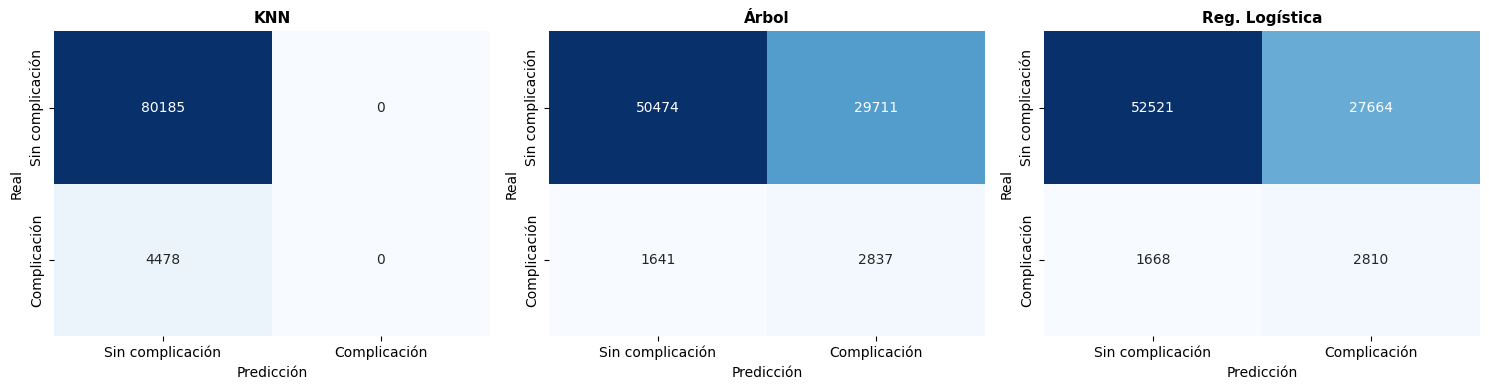

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
etiquetas = ['Sin complicación', 'Complicación']

for ax, (name, (y_pred, _)) in zip(axes.flatten(), models.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.set_ylabel('Real', fontsize=10)
    ax.set_xlabel('Predicción', fontsize=10)

plt.tight_layout()
plt.show()

---

## 9. Pipelines

Los pipelines encapsulan **imputación → (estandarización) → modelo**. Con `fit(X_train)`, cada paso aprende solo del train, y con `predict(X_test)` se aplican las medianas y escalas de train. Se entrenan con `X_train` **crudo (con NaN)** y deben reproducir los resultados del flujo manual.

In [29]:
pipelines = {
    'KNN': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                     ('model', KNeighborsClassifier(n_neighbors=best_k, n_jobs=-1))]),
    'Árbol': Pipeline([('imputer', SimpleImputer(strategy='median')),
                       ('model', DecisionTreeClassifier(max_depth=best_depth, min_samples_split=20,
                                                        class_weight='balanced', random_state=SEED))]),
    'Reg. Logística': Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()),
                                ('model', LogisticRegression(C=best_C, solver=best_solver, l1_ratio=0,
                                                             class_weight='balanced', max_iter=1000,
                                                             random_state=SEED))]),
}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    auc_pipe = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    auc_manual = metrics_df.set_index('Modelo').loc[name, 'ROC-AUC']
    print(f"{name:15s} (Pipeline): ROC-AUC = {auc_pipe:.4f} | manual = {auc_manual:.4f}")

KNN             (Pipeline): ROC-AUC = 0.6687 | manual = 0.6687


Árbol           (Pipeline): ROC-AUC = 0.6827 | manual = 0.6827


Reg. Logística  (Pipeline): ROC-AUC = 0.6947 | manual = 0.6947


---
## APÉNDICE

### Validación Cruzada: Estimación de Variabilidad
Con los hiperparámetros ya elegidos, `StratifiedKFold` (5 folds) mide la **estabilidad** de cada modelo. Se usan los **pipelines**: la imputación y el escalado se ajustan **dentro de cada fold**, sin fuga de información. Para que KNN sea manejable, la validación cruzada se hace sobre una **submuestra estratificada de 50,000 pacientes**.

In [30]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

idx_cv, _ = train_test_split(X.index, train_size=50_000, random_state=SEED, stratify=y)
X_cv, y_cv = X.loc[idx_cv], y.loc[idx_cv]

cv_results, cv_scores_dict = [], {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_cv, y_cv, cv=skf, scoring='roc_auc')
    cv_results.append({'Modelo': name, 'ROC-AUC Media': scores.mean(), 'Desv. Estándar': scores.std()})
    cv_scores_dict[name] = scores

cv_results_df = pd.DataFrame(cv_results)
cv_results_df.round(4)

,Modelo,ROC-AUC Media,Desv. Estándar
0,KNN,0.6524,0.0111
1,Árbol,0.6501,0.0099
2,Reg. Logística,0.6929,0.0087


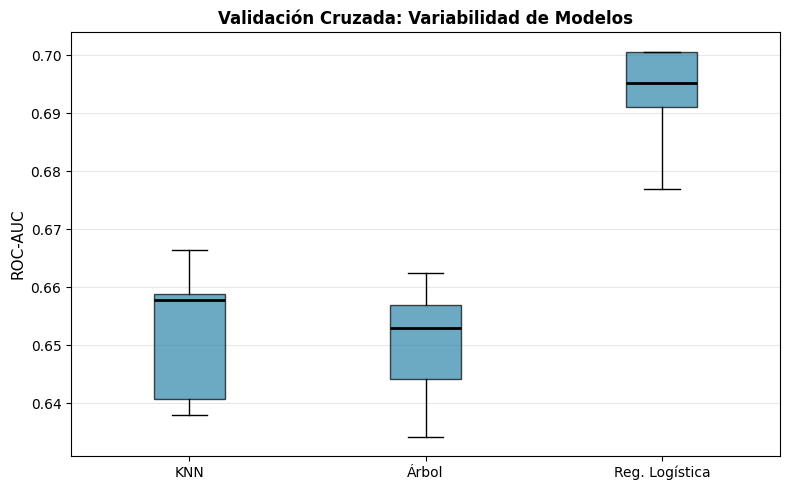

In [31]:
fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([cv_scores_dict[n] for n in pipelines], tick_labels=list(pipelines), patch_artist=True,
                medianprops=dict(color='black', linewidth=2))
for patch in bp['boxes']:
    patch.set_facecolor(color_accent1)
    patch.set_alpha(0.7)
ax.set_ylabel('ROC-AUC', fontsize=11)
ax.set_title('Validación Cruzada: Variabilidad de Modelos', fontsize=12, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Conclusiones
1. **Datos:** 423,314 pacientes, **28 variables** y 5.29% de complicaciones (desbalance ≈18:1).
   - No hay pacientes repetidos. Las 8 filas idénticas son pacientes distintos con los mismos valores y el mismo `y`, así que no se eliminan.
   - Los faltantes (3.9% sin medición de presión) se imputaron con la mediana de train y se conservó `sin_medicion_pa`.
   - Según la matriz de correlación, se eliminaron `dias_hosp` (Spearman 0.997 con `n_hospitalizaciones`) y `pad_media` (dependencia exacta con `presion_pulso` y `pas_media`).
2. **Mejor modelo: Regresión Logística** (AUC test = 0.695; en validación cruzada 0.693 ± 0.009). Le siguen el Árbol (0.683 en test) y KNN (0.669). La Regresión Logística también es la más **estable**: tiene la menor desviación en validación cruzada y no sobreajusta.
3. **Árbol y KNN prácticamente empatan.** En la validación cruzada (submuestra de 50k), el Árbol (0.650) y KNN (0.652) quedan casi iguales: con menos datos, un árbol de profundidad 7 sobreajusta más. La Regresión Logística sale primera en todas las evaluaciones.
4. **El accuracy engaña:** KNN tiene el mayor accuracy (94.7%) porque **no predice ninguna complicación** (recall = 0). Con `class_weight='balanced'`, el Árbol y la RL detectan ≈63% de los pacientes que se complicarán, a costa de muchos falsos positivos (precision ≈ 9%).
5. **KNN es el modelo más débil para estos datos:** su mejor k fue siempre el máximo de la grilla, por la alta dimensionalidad, el desbalance y el costo de inferencia (ver sección 5).
6. **Capacidad predictiva moderada (AUC ≈ 0.67–0.69).** Es esperable con datos administrativos sin laboratorio (creatinina, colesterol, HbA1c). Ningún modelo pasa de 0.85, así que no hay señales de fuga de información.
7. **Eliminar columnas no cambió la Regresión Logística** (AUC 0.6947 antes y después), lo que confirma que eran redundantes. El modelo queda más simple e interpretable.
8. **Los pipelines reproducen exactamente** los resultados del flujo manual: la imputación y el escalado se ajustan solo con train.
9. **Siguientes pasos:**
   - Ajustar el **umbral de decisión** según el costo de no detectar a un paciente en riesgo.
   - Aplicar `log1p` a gastos y conteos.
   - Agregar variables de laboratorio o de medicamentos antihipertensivos.